In [ ]:

import os

for file in os.listdir('/'):
    if file.endswith('.csv'):
        print(file)


Zomato Restaurant reviews (2).csv
Zomato Restaurant names and Metadata (1).csv


In [ ]:

import pandas as pd

# Read first CSV file
df1 = pd.read_csv('/Zomato Restaurant reviews (2).csv')

# Read second CSV file
df2 = pd.read_csv('/Zomato Restaurant names and Metadata (1).csv')

print("FIRST DATASET")
display(df1.head())

print("SECOND DATASET")
display(df2.head())


FIRST DATASET


,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5,"1 Review , 2 Followers",5/25/2019 15:54,0
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5,"3 Reviews , 2 Followers",5/25/2019 14:20,0
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5,"2 Reviews , 3 Followers",5/24/2019 22:54,0
3,Beyond Flavours,Swapnil Sarkar,Soumen das and Arun was a great guy. Only beca...,5,"1 Review , 1 Follower",5/24/2019 22:11,0
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and ba...,5,"3 Reviews , 2 Followers",5/24/2019 21:37,0


SECOND DATASET


,Name,Links,Cost,Collections,Cuisines,Timings
0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
1,Paradise,https://www.zomato.com/hyderabad/paradise-gach...,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",11 AM to 11 PM
2,Flechazo,https://www.zomato.com/hyderabad/flechazo-gach...,"1,300","Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts","11:30 AM to 4:30 PM, 6:30 PM to 11 PM"
3,Shah Ghouse Hotel & Restaurant,https://www.zomato.com/hyderabad/shah-ghouse-h...,800,Late Night Restaurants,"Biryani, North Indian, Chinese, Seafood, Bever...",12 Noon to 2 AM
4,Over The Moon Brew Company,https://www.zomato.com/hyderabad/over-the-moon...,"1,200","Best Bars & Pubs, Food Hygiene Rated Restauran...","Asian, Continental, North Indian, Chinese, Med...","12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12no..."


In [ ]:

# Check dataset sizes
print("First dataset shape:", df1.shape)
print("Second dataset shape:", df2.shape)

# Check duplicate restaurant names
print("Duplicates in second dataset:",
      df2['Name'].duplicated().sum())

# Check matching restaurant names
print("Common restaurants:",
      df1['Restaurant'].isin(df2['Name']).sum())


First dataset shape: (10000, 7)
Second dataset shape: (105, 6)
Duplicates in second dataset: 0
Common restaurants: 10000


In [ ]:

# Merge both datasets
df = pd.merge(
    df1,
    df2,
    left_on='Restaurant',
    right_on='Name',
    how='left'
)

# Remove duplicate restaurant name column
df.drop('Name', axis=1, inplace=True)

print("Merged Dataset:")
display(df.head())

print("Merged Dataset Shape:", df.shape)


Merged Dataset:


,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures,Links,Cost,Collections,Cuisines,Timings
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5,"1 Review , 2 Followers",5/25/2019 15:54,0,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5,"3 Reviews , 2 Followers",5/25/2019 14:20,0,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5,"2 Reviews , 3 Followers",5/24/2019 22:54,0,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
3,Beyond Flavours,Swapnil Sarkar,Soumen das and Arun was a great guy. Only beca...,5,"1 Review , 1 Follower",5/24/2019 22:11,0,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and ba...,5,"3 Reviews , 2 Followers",5/24/2019 21:37,0,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"


Merged Dataset Shape: (10000, 12)


In [ ]:

df.to_csv('Zomato_Merged_Dataset.csv', index=False)

print("Dataset merged and saved successfully!")


Dataset merged and saved successfully!


In [ ]:

# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:")
print(df.duplicated().sum())

# Dataset information
print("\nDataset Information:")
df.info()


Missing Values:
Restaurant        0
Reviewer         38
Review           45
Rating           38
Metadata         38
Time             38
Pictures          0
Links             0
Cost              0
Collections    5000
Cuisines          0
Timings         100
dtype: int64

Duplicate Rows:
36

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Restaurant   10000 non-null  object
 1   Reviewer     9962 non-null   object
 2   Review       9955 non-null   object
 3   Rating       9962 non-null   object
 4   Metadata     9962 non-null   object
 5   Time         9962 non-null   object
 6   Pictures     10000 non-null  int64 
 7   Links        10000 non-null  object
 8   Cost         10000 non-null  object
 9   Collections  5000 non-null   object
 10  Cuisines     10000 non-null  object
 11  Timings      9900 non-null   object
dtypes:

In [ ]:

# Check different rating values
print("Rating values:")
print(df['Rating'].value_counts().head(20))

# Check cost values
print("\nCost values:")
print(df['Cost'].value_counts().head(20))

# Check data types
print("\nData types:")
print(df.dtypes)


Rating values:
Rating
5       3832
4       2373
1       1735
3       1193
2        684
4.5       69
3.5       47
2.5       19
1.5        9
Like       1
Name: count, dtype: int64

Cost values:
Cost
500      1200
600       900
700       800
1,200     700
1,000     600
400       600
800       500
1,500     500
1,300     400
200       400
750       300
350       300
1,100     300
550       300
1,600     300
900       300
1,900     200
1,400     200
450       200
150       200
Name: count, dtype: int64

Data types:
Restaurant     object
Reviewer       object
Review         object
Rating         object
Metadata       object
Time           object
Pictures        int64
Links          object
Cost           object
Collections    object
Cuisines       object
Timings        object
dtype: object


In [ ]:

# Convert Rating into numeric values
df['Rating'] = pd.to_numeric(df['Rating'], errors='coerce')

# Convert Cost into numeric values
df['Cost'] = df['Cost'].astype(str).str.replace(',', '', regex=False)
df['Cost'] = pd.to_numeric(df['Cost'], errors='coerce')

# Check the results
print("Rating data type:", df['Rating'].dtype)
print("Cost data type:", df['Cost'].dtype)

print("\nRating values:")
print(df['Rating'].value_counts().sort_index())

print("\nCost values:")
print(df['Cost'].head(10))


Rating data type: float64
Cost data type: int64

Rating values:
Rating
1.0    1735
1.5       9
2.0     684
2.5      19
3.0    1193
3.5      47
4.0    2373
4.5      69
5.0    3832
Name: count, dtype: int64

Cost values:
0    800
1    800
2    800
3    800
4    800
5    800
6    800
7    800
8    800
9    800
Name: Cost, dtype: int64


In [ ]:

# Remove duplicate rows
df = df.drop_duplicates()

print("Duplicates remaining:", df.duplicated().sum())
print("Updated dataset shape:", df.shape)


Duplicates remaining: 0
Updated dataset shape: (9964, 12)


In [ ]:

# Fill missing categorical values
columns = ['Reviewer', 'Review', 'Metadata',
           'Time', 'Collections', 'Cuisines', 'Timings']

for col in columns:
    df[col] = df[col].fillna('Unknown')

print("Missing values after cleaning:")
print(df.isnull().sum())


Missing values after cleaning:
Restaurant     0
Reviewer       0
Review         0
Rating         3
Metadata       0
Time           0
Pictures       0
Links          0
Cost           0
Collections    0
Cuisines       0
Timings        0
dtype: int64


In [ ]:

# Create a copy of restaurant metadata
restaurants = df2.copy()

# Rename Name column
restaurants.rename(columns={'Name': 'Restaurant'}, inplace=True)

# Clean text columns
text_columns = ['Restaurant', 'Collections',
                'Cuisines', 'Timings', 'Links']

for col in text_columns:
    restaurants[col] = (
        restaurants[col]
        .fillna('')
        .astype(str)
        .str.strip()
    )

# Convert Cost into numeric format
restaurants['Cost'] = (
    restaurants['Cost']
    .astype(str)
    .str.replace(',', '', regex=False)
)

restaurants['Cost'] = pd.to_numeric(
    restaurants['Cost'], errors='coerce'
)

# Remove duplicate restaurants
restaurants = restaurants.drop_duplicates(
    subset=['Restaurant']
)

print("Restaurant dataset prepared!")
print("Total restaurants:", len(restaurants))

display(restaurants.head(10))


Restaurant dataset prepared!
Total restaurants: 105


,Restaurant,Links,Cost,Collections,Cuisines,Timings
0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
1,Paradise,https://www.zomato.com/hyderabad/paradise-gach...,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",11 AM to 11 PM
2,Flechazo,https://www.zomato.com/hyderabad/flechazo-gach...,1300,"Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts","11:30 AM to 4:30 PM, 6:30 PM to 11 PM"
3,Shah Ghouse Hotel & Restaurant,https://www.zomato.com/hyderabad/shah-ghouse-h...,800,Late Night Restaurants,"Biryani, North Indian, Chinese, Seafood, Bever...",12 Noon to 2 AM
4,Over The Moon Brew Company,https://www.zomato.com/hyderabad/over-the-moon...,1200,"Best Bars & Pubs, Food Hygiene Rated Restauran...","Asian, Continental, North Indian, Chinese, Med...","12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12no..."
5,The Fisherman's Wharf,https://www.zomato.com/hyderabad/the-fisherman...,1500,"Sunday Brunches, Corporate Favorites, Great Bu...","Seafood, Goan, North Indian, Continental, Asian","12Noon to 3:30PM, 4PM to 6:30PM, 7PM to 11:30P..."
6,eat.fit,https://www.zomato.com/hyderabad/eat-fit-gachi...,500,Food Hygiene Rated Restaurants in Hyderabad,"Healthy Food, North Indian, Continental, South...",7 AM to 10 PM
7,Shah Ghouse Spl Shawarma,https://www.zomato.com/hyderabad/shah-ghouse-s...,300,,Lebanese,12 Noon to 12 Midnight
8,Hyper Local,https://www.zomato.com/hyderabad/hyper-local-g...,1000,"Great Buffets, Live Sports Screenings, Best Ba...","American, Chinese, North Indian, Kebab, South ...",12 Noon to 12 Midnight
9,Cream Stone,https://www.zomato.com/hyderabad/cream-stone-g...,350,Frozen Delights,"Ice Cream, Desserts","10 AM to 1 AM (Mon-Thu), 10 AM to 1:30 AM (Fri..."


In [ ]:

print("Dataset shape:")
print(restaurants.shape)

print("\nMissing values:")
print(restaurants.isnull().sum())

print("\nAvailable cuisines:")
print(restaurants['Cuisines'].unique()[:20])


Dataset shape:
(105, 6)

Missing values:
Restaurant     0
Links          0
Cost           0
Collections    0
Cuisines       0
Timings        0
dtype: int64

Available cuisines:
['Chinese, Continental, Kebab, European, South Indian, North Indian'
 'Biryani, North Indian, Chinese'
 'Asian, Mediterranean, North Indian, Desserts'
 'Biryani, North Indian, Chinese, Seafood, Beverages'
 'Asian, Continental, North Indian, Chinese, Mediterranean'
 'Seafood, Goan, North Indian, Continental, Asian'
 'Healthy Food, North Indian, Continental, South Indian' 'Lebanese'
 'American, Chinese, North Indian, Kebab, South Indian'
 'Ice Cream, Desserts' 'Street Food, North Indian, Fast Food'
 'Mediterranean, North Indian, Kebab, BBQ'
 'Continental, American, Chinese' 'North Indian, Italian, Finger Food'
 'European, Mediterranean, North Indian' 'Burger, Fast Food'
 'North Indian' 'Chinese, North Indian'
 'North Indian, Chinese, Continental' 'North Indian, Chinese, Biryani']


In [ ]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

print("Machine Learning libraries imported successfully!")


Machine Learning libraries imported successfully!


In [ ]:

# Fill empty cuisine descriptions
restaurants['Cuisines'] = restaurants['Cuisines'].fillna('')

# Create TF-IDF model
tfidf = TfidfVectorizer()

# Convert cuisines into numerical features
cuisine_matrix = tfidf.fit_transform(
    restaurants['Cuisines']
)

print("TF-IDF conversion completed!")
print("Matrix shape:", cuisine_matrix.shape)


TF-IDF conversion completed!
Matrix shape: (105, 47)


In [ ]:

# Calculate similarity between restaurants
similarity_matrix = cosine_similarity(cuisine_matrix)

print("Cosine similarity calculated!")
print("Similarity matrix shape:", similarity_matrix.shape)


Cosine similarity calculated!
Similarity matrix shape: (105, 105)


In [ ]:

def recommend_restaurants(preferred_cuisine, max_cost=None, top_n=5):

    # Convert customer preference into TF-IDF
    user_vector = tfidf.transform([preferred_cuisine])

    # Calculate similarity with all restaurants
    scores = cosine_similarity(
        user_vector, cuisine_matrix
    ).flatten()

    # Store similarity scores
    results = restaurants.copy()
    results['Similarity'] = scores

    # Apply budget filter if provided
    if max_cost is not None:
        results = results[
            results['Cost'] <= max_cost
        ]

    # Sort by similarity
    results = results.sort_values(
        by='Similarity', ascending=False
    )

    # Display top recommendations
    return results[
        ['Restaurant', 'Cuisines', 'Cost', 'Similarity']
    ].head(top_n)


In [ ]:

recommendations = recommend_restaurants(
    preferred_cuisine='Biryani',
    max_cost=800,
    top_n=5
)

display(recommendations)


,Restaurant,Cuisines,Cost,Similarity
1,Paradise,"Biryani, North Indian, Chinese",800,0.704989
19,Pakwaan Grand,"North Indian, Chinese, Biryani",400,0.704989
35,Green Bawarchi Restaurant,"North Indian, Chinese, Biryani",700,0.704989
52,Biryanis And More,"North Indian, Biryani, Chinese",500,0.704989
51,Hitech Bawarchi Food Zone,"Biryani, North Indian, Chinese",500,0.704989


In [ ]:

def improved_recommendations(preferred_cuisine, max_cost, top_n=5):

    user_vector = tfidf.transform([preferred_cuisine])

    scores = cosine_similarity(
        user_vector, cuisine_matrix
    ).flatten()

    results = restaurants.copy()
    results['Similarity'] = scores

    # Filter restaurants by budget
    results = results[results['Cost'] <= max_cost]

    # Sort by similarity, then lower cost
    results = results.sort_values(
        by=['Similarity', 'Cost'],
        ascending=[False, True]
    )

    return results[
        ['Restaurant', 'Cuisines', 'Cost', 'Similarity']
    ].head(top_n)


In [ ]:

display(
    improved_recommendations(
        preferred_cuisine='Biryani',
        max_cost=800,
        top_n=5
    )
)


,Restaurant,Cuisines,Cost,Similarity
19,Pakwaan Grand,"North Indian, Chinese, Biryani",400,0.704989
51,Hitech Bawarchi Food Zone,"Biryani, North Indian, Chinese",500,0.704989
52,Biryanis And More,"North Indian, Biryani, Chinese",500,0.704989
102,Angaara Counts 3,"North Indian, Biryani, Chinese",500,0.704989
35,Green Bawarchi Restaurant,"North Indian, Chinese, Biryani",700,0.704989


In [ ]:

print("CHINESE RESTAURANTS")
display(recommend_restaurants('Chinese', 1000, 5))

print("NORTH INDIAN RESTAURANTS")
display(recommend_restaurants('North Indian', 1000, 5))

print("ITALIAN RESTAURANTS")
display(recommend_restaurants('Italian', 1500, 5))


CHINESE RESTAURANTS


,Restaurant,Cuisines,Cost,Similarity
17,Hotel Zara Hi-Fi,"Chinese, North Indian",400,0.660032
64,Hyderabad Chefs,"North Indian, Chinese",600,0.660032
81,Delhi-39,"North Indian, Chinese",600,0.660032
57,Being Hungry,"North Indian, Chinese",450,0.660032
95,Desi Bytes,"North Indian, Chinese",400,0.660032


NORTH INDIAN RESTAURANTS


,Restaurant,Cuisines,Cost,Similarity
16,NorFest - The Dhaba,North Indian,550,1.000000
20,13 Dhaba,North Indian,450,1.000000
98,Triptify,North Indian,400,1.000000
57,Being Hungry,"North Indian, Chinese",450,0.751237
81,Delhi-39,"North Indian, Chinese",600,0.751237


ITALIAN RESTAURANTS


,Restaurant,Cuisines,Cost,Similarity
53,Diners Pavilion,"Chinese, Continental, Italian",1200,0.680108
68,The Tilt Bar Republic,"North Indian, Continental, Italian",1500,0.662062
60,PourHouse7,"North Indian, Continental, Chinese, Italian",1200,0.610194
38,The Glass Onion,"North Indian, Continental, Italian, Asian",1200,0.555709
77,Squeeze @ The Lime,"Italian, North Indian, Chinese, Salad",650,0.523830


In [ ]:
recommendations = improved_recommendations(
    preferred_cuisine='Pizza',
    max_cost=1000,
    top_n=5
)

display(recommendations)

,Restaurant,Cuisines,Cost,Similarity
88,Domino's Pizza,"Fast Food, Pizza",400,0.784135
23,Amul,"Ice Cream, Desserts",150,0.000000
89,Mohammedia Shawarma,"Street Food, Arabian",150,0.000000
29,Hunger Maggi Point,Fast Food,200,0.000000
54,Asian Meal Box,Asian,200,0.000000


In [ ]:

def improved_recommendations(preferred_cuisine, max_cost, top_n=5):

    user_vector = tfidf.transform([preferred_cuisine])
    scores = cosine_similarity(user_vector, cuisine_matrix).flatten()

    results = restaurants.copy()
    results['Similarity'] = scores

    results = results[results['Cost'] <= max_cost]

    # Remove restaurants with zero similarity
    results = results[results['Similarity'] > 0]

    results = results.sort_values(
        by=['Similarity', 'Cost'],
        ascending=[False, True]
    )

    return results[['Restaurant', 'Cuisines', 'Cost', 'Similarity']].head(top_n)


In [ ]:
display(improved_recommendations('Pizza', 1000, 5))

,Restaurant,Cuisines,Cost,Similarity
88,Domino's Pizza,"Fast Food, Pizza",400,0.784135


In [ ]:
cuisine = input("Enter your preferred cuisine: ")
budget = float(input("Enter your maximum budget: "))

result = improved_recommendations(cuisine, budget, 5)

print("\nRecommended Restaurants:")
display(result)

Enter your preferred cuisine: biryani
Enter your maximum budget: 800

Recommended Restaurants:


,Restaurant,Cuisines,Cost,Similarity
19,Pakwaan Grand,"North Indian, Chinese, Biryani",400,0.704989
51,Hitech Bawarchi Food Zone,"Biryani, North Indian, Chinese",500,0.704989
52,Biryanis And More,"North Indian, Biryani, Chinese",500,0.704989
102,Angaara Counts 3,"North Indian, Biryani, Chinese",500,0.704989
35,Green Bawarchi Restaurant,"North Indian, Chinese, Biryani",700,0.704989


In [ ]:
!pip install gradio

In [ ]:

import gradio as gr

def get_recommendations(cuisine, budget):

    result = improved_recommendations(
        cuisine,
        budget,
        top_n=5
    )

    if result.empty:
        return result

    return result

demo = gr.Interface(
    fn=get_recommendations,

    inputs=[
        gr.Textbox(
            label="Enter Your Favourite Cuisine",
            placeholder="Example: Biryani"
        ),

        gr.Number(
            label="Maximum Budget (₹)",
            value=800
        )
    ],

    outputs=gr.Dataframe(
        label="Recommended Restaurants"
    ),

    title="🍽️ Zomato Restaurant Recommendation System",

    description="Find the best restaurants based on your favourite cuisine and budget."
)

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://cc1cd4f1af2a54c1e6.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:

import gradio as gr

def get_recommendations(cuisine, budget):

    if not cuisine or not cuisine.strip():
        return None, "Please enter a cuisine."

    if budget is None or budget <= 0:
        return None, "Please enter a valid budget."

    result = improved_recommendations(
        cuisine,
        budget,
        top_n=5
    )

    if result.empty:
        return None, "No matching restaurants found. Try another cuisine or budget."

    return result, "Here are your recommended restaurants!"

with gr.Blocks(theme=gr.themes.Soft(), title="Zomato AI Recommender") as demo:

    gr.Markdown(
        """
        # 🍽️ Zomato Restaurant Recommendation System
        ### Discover restaurants based on your favourite cuisine and budget!
        """
    )

    with gr.Row():
        cuisine = gr.Textbox(
            label="Favourite Cuisine",
            placeholder="Example: Biryani"
        )

        budget = gr.Number(
            label="Maximum Budget (₹)",
            value=800
        )

    recommend_btn = gr.Button(
        "🔍 Recommend Restaurants",
        variant="primary"
    )

    message = gr.Markdown()

    output = gr.Dataframe(
        label="Top 5 Recommended Restaurants",
        interactive=False
    )

    recommend_btn.click(
        fn=get_recommendations,
        inputs=[cuisine, budget],
        outputs=[output, message]
    )

    gr.Examples(
        examples=[
            ["Biryani", 800],
            ["Pizza", 1000],
            ["Chinese", 600]
        ],
        inputs=[cuisine, budget]
    )

demo.launch(share=True)


/tmp/ipykernel_6652/1417429844.py:22: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft(), title="Zomato AI Recommender") as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://1cfb17badfb385d7f4.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:

# Convert ratings into numbers
df1['Rating'] = pd.to_numeric(
    df1['Rating'],
    errors='coerce'
)

# Calculate average rating for each restaurant
rating_summary = df1.groupby('Restaurant').agg(
    Average_Rating=('Rating', 'mean'),
    Review_Count=('Rating', 'count')
).reset_index()

# Add ratings to restaurant dataset
restaurants = restaurants.merge(
    rating_summary,
    on='Restaurant',
    how='left'
)

# Display restaurant ratings
display(
    restaurants[
        ['Restaurant', 'Cuisines', 'Cost',
         'Average_Rating', 'Review_Count']
    ].head(10)
)


,Restaurant,Cuisines,Cost,Average_Rating,Review_Count
0,Beyond Flavours,"Chinese, Continental, Kebab, European, South I...",800,4.280,100.0
1,Paradise,"Biryani, North Indian, Chinese",800,4.700,100.0
2,Flechazo,"Asian, Mediterranean, North Indian, Desserts",1300,4.660,100.0
3,Shah Ghouse Hotel & Restaurant,"Biryani, North Indian, Chinese, Seafood, Bever...",800,3.210,100.0
4,Over The Moon Brew Company,"Asian, Continental, North Indian, Chinese, Med...",1200,4.340,100.0
5,The Fisherman's Wharf,"Seafood, Goan, North Indian, Continental, Asian",1500,4.220,100.0
6,eat.fit,"Healthy Food, North Indian, Continental, South...",500,3.200,100.0
7,Shah Ghouse Spl Shawarma,Lebanese,300,3.430,100.0
8,Hyper Local,"American, Chinese, North Indian, Kebab, South ...",1000,3.640,100.0
9,Cream Stone,"Ice Cream, Desserts",350,3.845,100.0


In [ ]:

def final_recommendations(preferred_cuisine, max_cost, top_n=5):

    user_vector = tfidf.transform([preferred_cuisine])

    scores = cosine_similarity(
        user_vector,
        cuisine_matrix
    ).flatten()

    results = restaurants.copy()

    results['Similarity'] = scores

    results = results[
        (results['Cost'] <= max_cost) &
        (results['Similarity'] > 0)
    ].copy()

    results['Average_Rating'] = results[
        'Average_Rating'
    ].fillna(0)

    results['Final_Score'] = (
        0.7 * results['Similarity'] +
        0.3 * (results['Average_Rating'] / 5)
    )

    results = results.sort_values(
        by='Final_Score',
        ascending=False
    )

    return results[
        ['Restaurant', 'Cuisines', 'Cost',
         'Average_Rating', 'Similarity', 'Final_Score']
    ].head(top_n)


In [ ]:
display(
    final_recommendations(
        preferred_cuisine='Biryani',
        max_cost=800,
        top_n=5
    )
)

,Restaurant,Cuisines,Cost,Average_Rating,Similarity,Final_Score
1,Paradise,"Biryani, North Indian, Chinese",800,4.70,0.704989,0.775492
52,Biryanis And More,"North Indian, Biryani, Chinese",500,3.74,0.704989,0.717892
35,Green Bawarchi Restaurant,"North Indian, Chinese, Biryani",700,3.49,0.704989,0.702892
51,Hitech Bawarchi Food Zone,"Biryani, North Indian, Chinese",500,3.05,0.704989,0.676492
19,Pakwaan Grand,"North Indian, Chinese, Biryani",400,2.71,0.704989,0.656092


In [ ]:

import gradio as gr

def get_final_results(cuisine, budget):

    if not cuisine or not cuisine.strip():
        return None

    if budget is None or budget <= 0:
        return None

    return final_recommendations(
        cuisine,
        budget,
        top_n=5
    )

with gr.Blocks(
    theme=gr.themes.Soft(),
    title="Zomato Smart Recommendation"
) as demo:

    gr.Markdown(
        """
        # 🍽️ Zomato Smart Restaurant Finder
        ### Find restaurants using AI, cuisine preferences and customer ratings!
        """
    )

    with gr.Row():
        cuisine = gr.Textbox(
            label="Favourite Cuisine",
            placeholder="Example: Biryani"
        )

        budget = gr.Number(
            label="Maximum Budget (₹)",
            value=800
        )

    btn = gr.Button(
        "Find Restaurants 🔍",
        variant="primary"
    )

    output = gr.Dataframe(
        label="Recommended Restaurants",
        interactive=False
    )

    btn.click(
        get_final_results,
        inputs=[cuisine, budget],
        outputs=output
    )

demo.launch(share=True)


/tmp/ipykernel_6652/2799566469.py:17: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://1b21a653ad97ae7b64.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


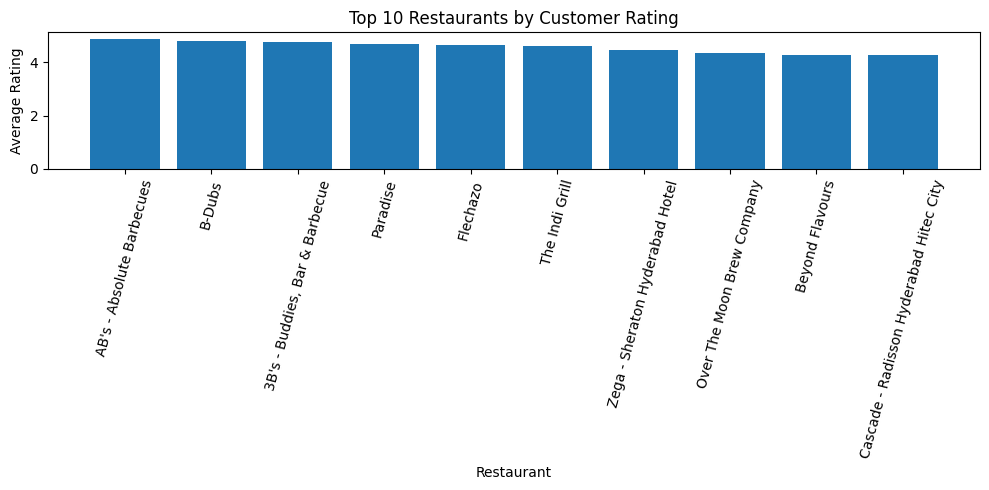

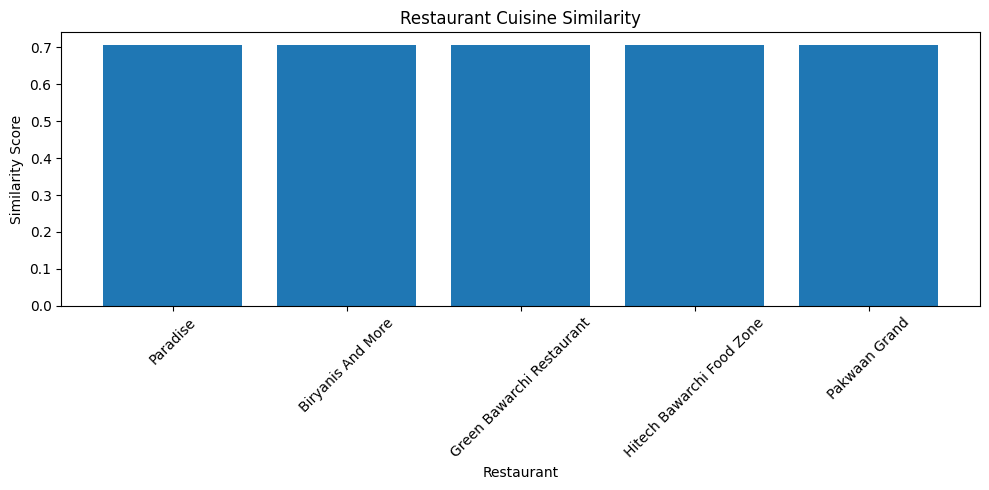

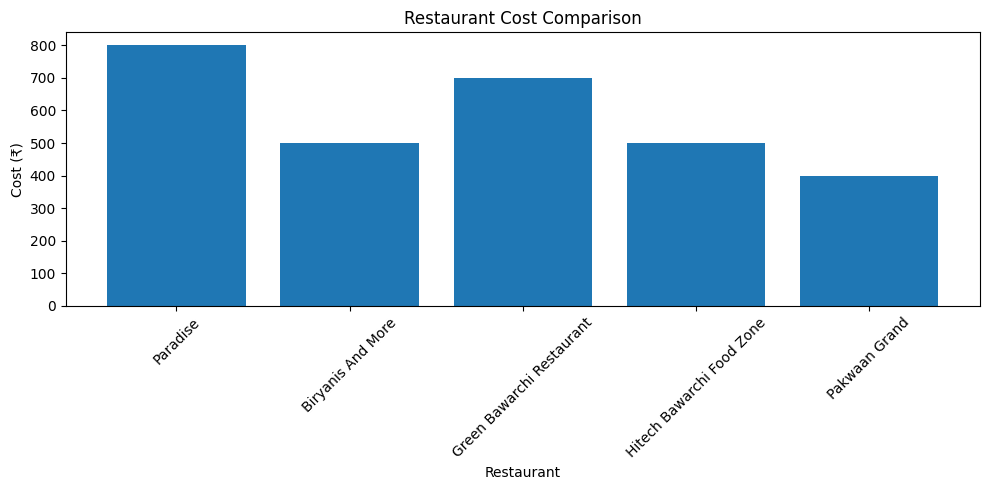

In [ ]:

import matplotlib.pyplot as plt

# Graph 1: Top 10 restaurants by rating
top_rated = restaurants.sort_values(
    by='Average_Rating',
    ascending=False
).head(10)

plt.figure(figsize=(10, 5))
plt.bar(
    top_rated['Restaurant'],
    top_rated['Average_Rating']
)
plt.xticks(rotation=75)
plt.title('Top 10 Restaurants by Customer Rating')
plt.xlabel('Restaurant')
plt.ylabel('Average Rating')
plt.tight_layout()
plt.show()


# Graph 2: Cuisine similarity scores
test_results = final_recommendations(
    'Biryani', 800, 5
)

plt.figure(figsize=(10, 5))
plt.bar(
    test_results['Restaurant'],
    test_results['Similarity']
)
plt.xticks(rotation=45)
plt.title('Restaurant Cuisine Similarity')
plt.xlabel('Restaurant')
plt.ylabel('Similarity Score')
plt.tight_layout()
plt.show()


# Graph 3: Restaurant cost comparison
plt.figure(figsize=(10, 5))
plt.bar(
    test_results['Restaurant'],
    test_results['Cost']
)
plt.xticks(rotation=45)
plt.title('Restaurant Cost Comparison')
plt.xlabel('Restaurant')
plt.ylabel('Cost (₹)')
plt.tight_layout()
plt.show()


In [ ]:

# Generate recommendations
result = final_recommendations(
    preferred_cuisine='Biryani',
    max_cost=800,
    top_n=5
)

# Calculate evaluation metrics
print("ZOMATO RECOMMENDATION SYSTEM - EVALUATION")
print("------------------------------------------")

print("Total Restaurants:", len(restaurants))

print("Average Restaurant Rating:",
      round(restaurants['Average_Rating'].mean(), 2))

print("Recommended Restaurants:", len(result))

print("Average Similarity Score:",
      round(result['Similarity'].mean(), 4))

print("Average Final Recommendation Score:",
      round(result['Final_Score'].mean(), 4))

print("\nEvaluation Completed Successfully!")


ZOMATO RECOMMENDATION SYSTEM - EVALUATION
------------------------------------------
Total Restaurants: 105
Average Restaurant Rating: 3.6
Recommended Restaurants: 5
Average Similarity Score: 0.705
Average Final Recommendation Score: 0.7058

Evaluation Completed Successfully!


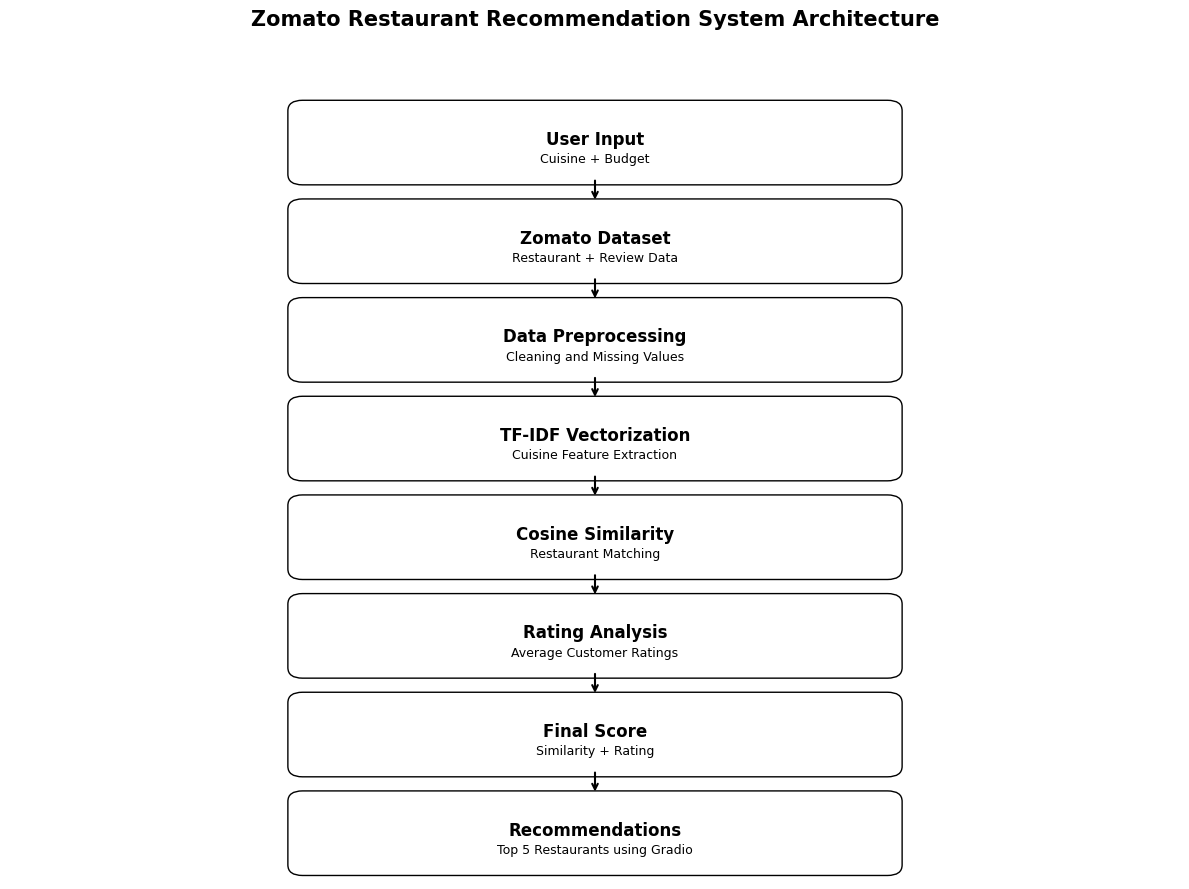

In [ ]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(12, 9))
ax.set_xlim(0, 12)
ax.set_ylim(0, 12)
ax.axis('off')

steps = [
    ("User Input", "Cuisine + Budget"),
    ("Zomato Dataset", "Restaurant + Review Data"),
    ("Data Preprocessing", "Cleaning and Missing Values"),
    ("TF-IDF Vectorization", "Cuisine Feature Extraction"),
    ("Cosine Similarity", "Restaurant Matching"),
    ("Rating Analysis", "Average Customer Ratings"),
    ("Final Score", "Similarity + Rating"),
    ("Recommendations", "Top 5 Restaurants using Gradio")
]

y = 10.5

for title, desc in steps:
    box = FancyBboxPatch(
        (3, y-0.5), 6, 0.9,
        boxstyle="round,pad=0.15",
        edgecolor="black",
        facecolor="white"
    )
    ax.add_patch(box)

    ax.text(6, y, title, ha='center',
            va='center', fontsize=12, weight='bold')
    ax.text(6, y-0.28, desc, ha='center',
            va='center', fontsize=9)

    if title != "Recommendations":
        ax.annotate(
            "", xy=(6, y-0.9),
            xytext=(6, y-0.55),
            arrowprops=dict(arrowstyle="->", lw=1.5)
        )

    y -= 1.4

plt.title(
    "Zomato Restaurant Recommendation System Architecture",
    fontsize=15,
    weight='bold'
)
plt.tight_layout()
plt.savefig("Zomato_System_Architecture.png", dpi=300)
plt.show()


In [ ]:
!pip install vaderSentiment

In [ ]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

def analyze_sentiment(review):
    if pd.isna(review):
        return "Unknown"

    score = analyzer.polarity_scores(str(review))['compound']

    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"

# Analyze customer reviews
df1['Sentiment'] = df1['Review'].apply(analyze_sentiment)

# Display results
display(df1[['Restaurant', 'Review', 'Rating', 'Sentiment']].head(10))

# Count sentiment categories
print("\nSentiment Analysis Summary:")
print(df1['Sentiment'].value_counts())

,Restaurant,Review,Rating,Sentiment
0,Beyond Flavours,"The ambience was good, food was quite good . h...",5.0,Positive
1,Beyond Flavours,Ambience is too good for a pleasant evening. S...,5.0,Positive
2,Beyond Flavours,A must try.. great food great ambience. Thnx f...,5.0,Positive
3,Beyond Flavours,Soumen das and Arun was a great guy. Only beca...,5.0,Positive
4,Beyond Flavours,Food is good.we ordered Kodi drumsticks and ba...,5.0,Positive
5,Beyond Flavours,"Ambiance is good, service is good, food is aPr...",5.0,Positive
6,Beyond Flavours,"Its a very nice place, ambience is different, ...",5.0,Positive
7,Beyond Flavours,Well after reading so many reviews finally vis...,4.0,Positive
8,Beyond Flavours,"Excellent food , specially if you like spicy f...",5.0,Positive
9,Beyond Flavours,Came for the birthday treat of a close friend....,5.0,Positive



Sentiment Analysis Summary:
Sentiment
Positive    7391
Negative    1847
Neutral      717
Unknown       45
Name: count, dtype: int64


In [1]:
def filter_by_rating(min_rating):
    result = final_recommendations(
        preferred_cuisine='Biryani',
        max_cost=800,
        top_n=20
    )

    result = result[
        result['Average_Rating'] >= min_rating
    ]

    return result.head(5)

display(filter_by_rating(4.0))

NameError: name 'final_recommendations' is not defined

In [2]:
def final_recommendations(preferred_cuisine, max_cost, top_n=5):

    user_vector = tfidf.transform([preferred_cuisine])

    scores = cosine_similarity(
        user_vector, cuisine_matrix
    ).flatten()

    results = restaurants.copy()
    results['Similarity'] = scores

    results = results[
        (results['Cost'] <= max_cost) &
        (results['Similarity'] > 0)
    ].copy()

    results['Average_Rating'] = results['Average_Rating'].fillna(0)

    results['Final_Score'] = (
        0.7 * results['Similarity'] +
        0.3 * (results['Average_Rating'] / 5)
    )

    results = results.sort_values(
        by='Final_Score',
        ascending=False
    )

    return results[
        ['Restaurant', 'Cuisines', 'Cost',
         'Average_Rating', 'Similarity', 'Final_Score']
    ].head(top_n)

In [3]:
def filter_by_rating(min_rating):
    result = final_recommendations(
        preferred_cuisine='Biryani',
        max_cost=800,
        top_n=20
    )

    result = result[
        result['Average_Rating'] >= min_rating
    ]

    return result.head(5)

display(filter_by_rating(4.0))

NameError: name 'tfidf' is not defined

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

restaurants['Cuisines'] = restaurants['Cuisines'].fillna('')

tfidf = TfidfVectorizer()

cuisine_matrix = tfidf.fit_transform(
    restaurants['Cuisines']
)

similarity_matrix = cosine_similarity(cuisine_matrix)

print("TF-IDF and Cosine Similarity restored successfully!")

NameError: name 'restaurants' is not defined

In [5]:
import pandas as pd

df2 = pd.read_csv('/Zomato Restaurant names and Metadata (1).csv')

restaurants = df2.copy()

restaurants.rename(
    columns={'Name': 'Restaurant'},
    inplace=True
)

text_columns = [
    'Restaurant', 'Collections',
    'Cuisines', 'Timings', 'Links'
]

for col in text_columns:
    restaurants[col] = (
        restaurants[col]
        .fillna('')
        .astype(str)
        .str.strip()
    )

restaurants['Cost'] = (
    restaurants['Cost']
    .astype(str)
    .str.replace(',', '', regex=False)
)

restaurants['Cost'] = pd.to_numeric(
    restaurants['Cost'], errors='coerce'
)

restaurants = restaurants.drop_duplicates(
    subset=['Restaurant']
)

print("Restaurant dataset restored!")
print("Total Restaurants:", len(restaurants))

FileNotFoundError: [Errno 2] No such file or directory: '/Zomato Restaurant names and Metadata (1).csv'

In [6]:
from google.colab import files

uploaded = files.upload()

Saving Zomato Restaurant names and Metadata (1) (1).csv to Zomato Restaurant names and Metadata (1) (1).csv


In [8]:
from google.colab import files

uploaded = files.upload()

Saving Zomato Restaurant reviews (2).csv to Zomato Restaurant reviews (2).csv


In [9]:
import os

print(os.listdir('/content'))

['.config', 'Zomato Restaurant names and Metadata (1) (1).csv', 'Zomato Restaurant reviews (2).csv', 'sample_data']


In [10]:
import pandas as pd

df1 = pd.read_csv('/content/Zomato Restaurant reviews (2).csv')
df2 = pd.read_csv('/content/Zomato Restaurant names and Metadata (1) (1).csv')

print("Reviews Dataset:", df1.shape)
print("Restaurant Dataset:", df2.shape)

print("Both datasets loaded successfully!")

Reviews Dataset: (10000, 7)
Restaurant Dataset: (105, 6)
Both datasets loaded successfully!


In [11]:
# Prepare restaurant data
restaurants = df2.copy()

restaurants.rename(
    columns={'Name': 'Restaurant'},
    inplace=True
)

text_columns = [
    'Restaurant', 'Collections',
    'Cuisines', 'Timings', 'Links'
]

for col in text_columns:
    restaurants[col] = (
        restaurants[col]
        .fillna('')
        .astype(str)
        .str.strip()
    )

restaurants['Cost'] = (
    restaurants['Cost']
    .astype(str)
    .str.replace(',', '', regex=False)
)

restaurants['Cost'] = pd.to_numeric(
    restaurants['Cost'], errors='coerce'
)

restaurants = restaurants.drop_duplicates(
    subset=['Restaurant']
)

# Calculate customer ratings
df1['Rating'] = pd.to_numeric(
    df1['Rating'], errors='coerce'
)

rating_summary = df1.groupby('Restaurant').agg(
    Average_Rating=('Rating', 'mean'),
    Review_Count=('Rating', 'count')
).reset_index()

# Add ratings to restaurant data
restaurants = restaurants.merge(
    rating_summary,
    on='Restaurant',
    how='left'
)

print("Restaurant data and ratings restored!")
display(
    restaurants[
        ['Restaurant', 'Cost', 'Average_Rating', 'Review_Count']
    ].head(10)
)

Restaurant data and ratings restored!


,Restaurant,Cost,Average_Rating,Review_Count
0,Beyond Flavours,800,4.280,100.0
1,Paradise,800,4.700,100.0
2,Flechazo,1300,4.660,100.0
3,Shah Ghouse Hotel & Restaurant,800,3.210,100.0
4,Over The Moon Brew Company,1200,4.340,100.0
5,The Fisherman's Wharf,1500,4.220,100.0
6,eat.fit,500,3.200,100.0
7,Shah Ghouse Spl Shawarma,300,3.430,100.0
8,Hyper Local,1000,3.640,100.0
9,Cream Stone,350,3.845,100.0


In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

restaurants['Cuisines'] = restaurants['Cuisines'].fillna('')

tfidf = TfidfVectorizer()

cuisine_matrix = tfidf.fit_transform(
    restaurants['Cuisines']
)

similarity_matrix = cosine_similarity(cuisine_matrix)

print("TF-IDF restored successfully!")
print("Cosine Similarity restored successfully!")
print("Matrix Shape:", cuisine_matrix.shape)

TF-IDF restored successfully!
Cosine Similarity restored successfully!
Matrix Shape: (105, 47)


In [13]:
def final_recommendations(preferred_cuisine, max_cost, top_n=5):

    user_vector = tfidf.transform([preferred_cuisine])

    scores = cosine_similarity(
        user_vector, cuisine_matrix
    ).flatten()

    results = restaurants.copy()
    results['Similarity'] = scores

    results = results[
        (results['Cost'] <= max_cost) &
        (results['Similarity'] > 0)
    ].copy()

    results['Average_Rating'] = (
        results['Average_Rating'].fillna(0)
    )

    results['Final_Score'] = (
        0.7 * results['Similarity'] +
        0.3 * (results['Average_Rating'] / 5)
    )

    results = results.sort_values(
        by='Final_Score',
        ascending=False
    )

    return results[
        ['Restaurant', 'Cuisines', 'Cost',
         'Average_Rating', 'Similarity', 'Final_Score']
    ].head(top_n)

print("Final recommendation function restored!")

Final recommendation function restored!


In [14]:
def filter_by_rating(min_rating):

    result = final_recommendations(
        preferred_cuisine='Biryani',
        max_cost=800,
        top_n=20
    )

    result = result[
        result['Average_Rating'] >= min_rating
    ]

    return result.head(5)


display(filter_by_rating(4.0))

,Restaurant,Cuisines,Cost,Average_Rating,Similarity,Final_Score
1,Paradise,"Biryani, North Indian, Chinese",800,4.7,0.704989,0.775492


In [15]:
def explain_recommendation(cuisine, budget):

    result = final_recommendations(
        cuisine,
        budget,
        top_n=5
    )

    for index, row in result.iterrows():

        print("Restaurant:", row['Restaurant'])
        print("Cuisine:", row['Cuisines'])
        print("Cost: ₹", row['Cost'])
        print("Rating:", row['Average_Rating'])
        print("Reason: Matches your cuisine preference,")
        print("fits your budget and has customer ratings.")
        print("-" * 50)


explain_recommendation("Biryani", 800)

Restaurant: Paradise
Cuisine: Biryani, North Indian, Chinese
Cost: ₹ 800
Rating: 4.7
Reason: Matches your cuisine preference,
fits your budget and has customer ratings.
--------------------------------------------------
Restaurant: Biryanis And More
Cuisine: North Indian, Biryani, Chinese
Cost: ₹ 500
Rating: 3.74
Reason: Matches your cuisine preference,
fits your budget and has customer ratings.
--------------------------------------------------
Restaurant: Green Bawarchi Restaurant
Cuisine: North Indian, Chinese, Biryani
Cost: ₹ 700
Rating: 3.49
Reason: Matches your cuisine preference,
fits your budget and has customer ratings.
--------------------------------------------------
Restaurant: Hitech Bawarchi Food Zone
Cuisine: Biryani, North Indian, Chinese
Cost: ₹ 500
Rating: 3.05
Reason: Matches your cuisine preference,
fits your budget and has customer ratings.
--------------------------------------------------
Restaurant: Pakwaan Grand
Cuisine: North Indian, Chinese, Biryani
Cost: ₹ 

In [16]:
from google.colab import files

result = final_recommendations(
    preferred_cuisine="Biryani",
    max_cost=800,
    top_n=5
)

result.to_csv(
    "Zomato_Recommendations.csv",
    index=False
)

files.download("Zomato_Recommendations.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
!pip install vaderSentiment

In [18]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

def analyze_sentiment(review):

    if pd.isna(review):
        return "Unknown"

    score = analyzer.polarity_scores(str(review))['compound']

    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"

df1['Sentiment'] = df1['Review'].apply(analyze_sentiment)

print("Sentiment Analysis Completed!")
print(df1['Sentiment'].value_counts())

Sentiment Analysis Completed!
Sentiment
Positive    7391
Negative    1847
Neutral      717
Unknown       45
Name: count, dtype: int64


In [19]:
print("ZOMATO ANALYTICS DASHBOARD")
print("=" * 40)

print("Total Restaurants:", len(restaurants))

print(
    "Average Restaurant Rating:",
    round(restaurants['Average_Rating'].mean(), 2)
)

print("\nCUSTOMER SENTIMENT")
print(df1['Sentiment'].value_counts())

print("\nTOP 5 RATED RESTAURANTS")

top_restaurants = restaurants.sort_values(
    by='Average_Rating',
    ascending=False
)

display(
    top_restaurants[
        ['Restaurant', 'Average_Rating', 'Review_Count']
    ].head(5)
)

print("\nDASHBOARD STATISTICS GENERATED!")

ZOMATO ANALYTICS DASHBOARD
Total Restaurants: 105
Average Restaurant Rating: 3.6

CUSTOMER SENTIMENT
Sentiment
Positive    7391
Negative    1847
Neutral      717
Unknown       45
Name: count, dtype: int64

TOP 5 RATED RESTAURANTS


,Restaurant,Average_Rating,Review_Count
14,AB's - Absolute Barbecues,4.88,100.0
22,B-Dubs,4.81,100.0
27,"3B's - Buddies, Bar & Barbecue",4.76,100.0
1,Paradise,4.70,100.0
2,Flechazo,4.66,100.0



DASHBOARD STATISTICS GENERATED!


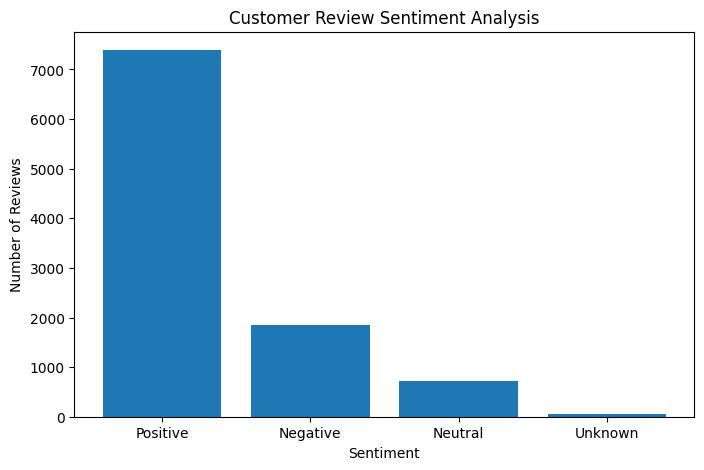

In [20]:
import matplotlib.pyplot as plt

sentiment_counts = df1['Sentiment'].value_counts()

plt.figure(figsize=(8, 5))

plt.bar(
    sentiment_counts.index,
    sentiment_counts.values
)

plt.title("Customer Review Sentiment Analysis")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

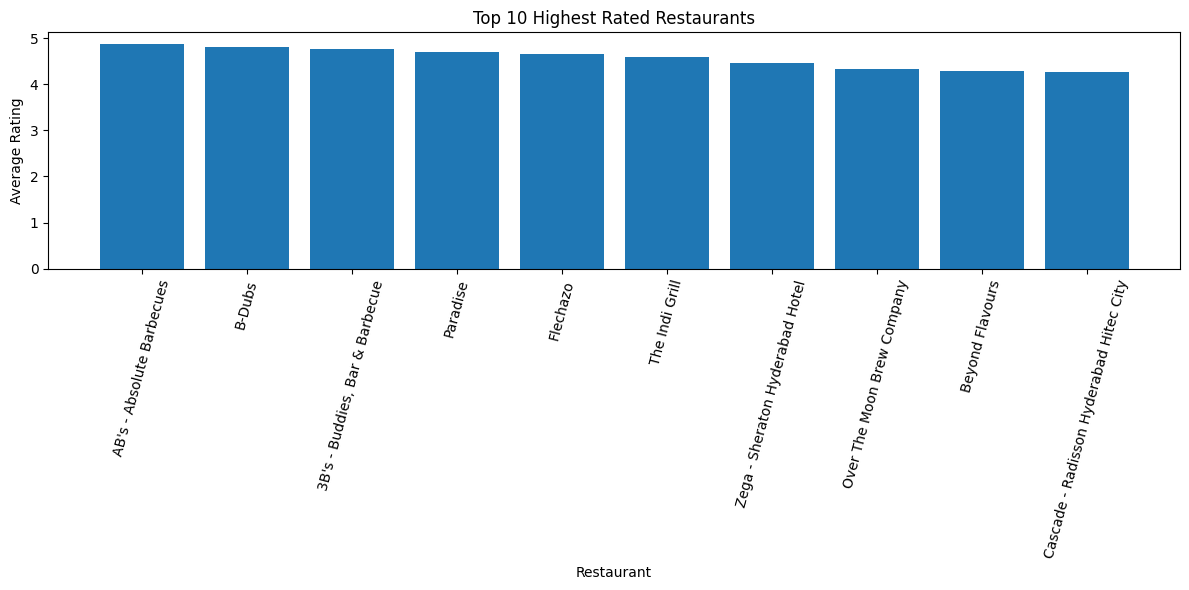

In [21]:
import matplotlib.pyplot as plt

top10 = restaurants.sort_values(
    by='Average_Rating',
    ascending=False
).head(10)

plt.figure(figsize=(12, 6))

plt.bar(
    top10['Restaurant'],
    top10['Average_Rating']
)

plt.title("Top 10 Highest Rated Restaurants")
plt.xlabel("Restaurant")
plt.ylabel("Average Rating")
plt.xticks(rotation=75)

plt.tight_layout()
plt.show()

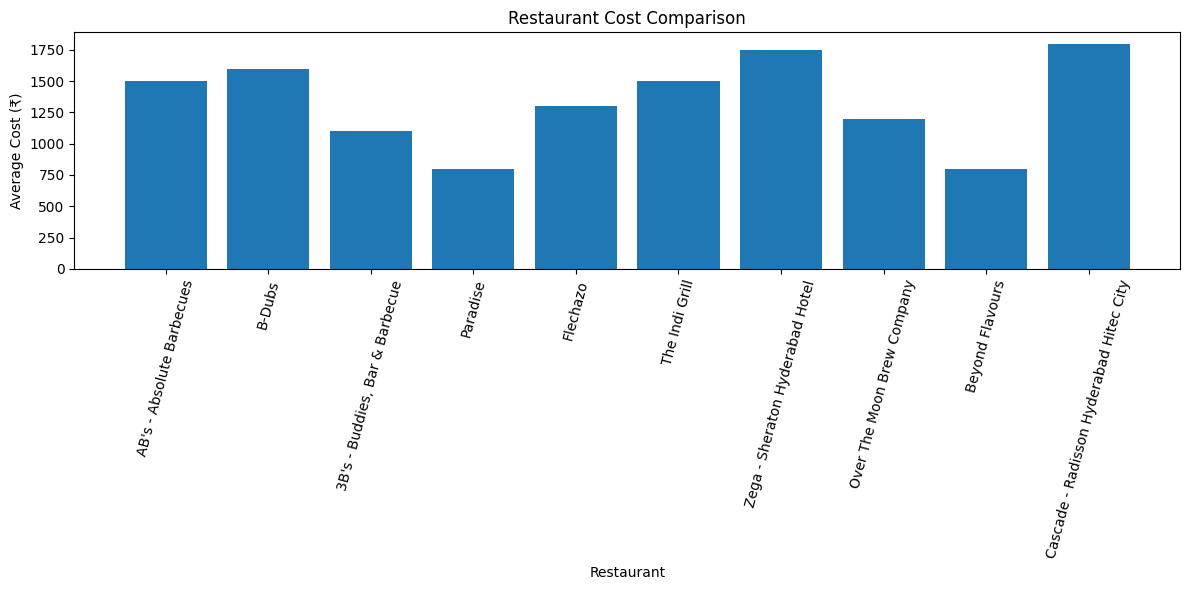

In [22]:
import matplotlib.pyplot as plt

top10_cost = restaurants.sort_values(
    by='Average_Rating',
    ascending=False
).head(10)

plt.figure(figsize=(12, 6))

plt.bar(
    top10_cost['Restaurant'],
    top10_cost['Cost']
)

plt.title("Restaurant Cost Comparison")
plt.xlabel("Restaurant")
plt.ylabel("Average Cost (₹)")
plt.xticks(rotation=75)

plt.tight_layout()
plt.show()

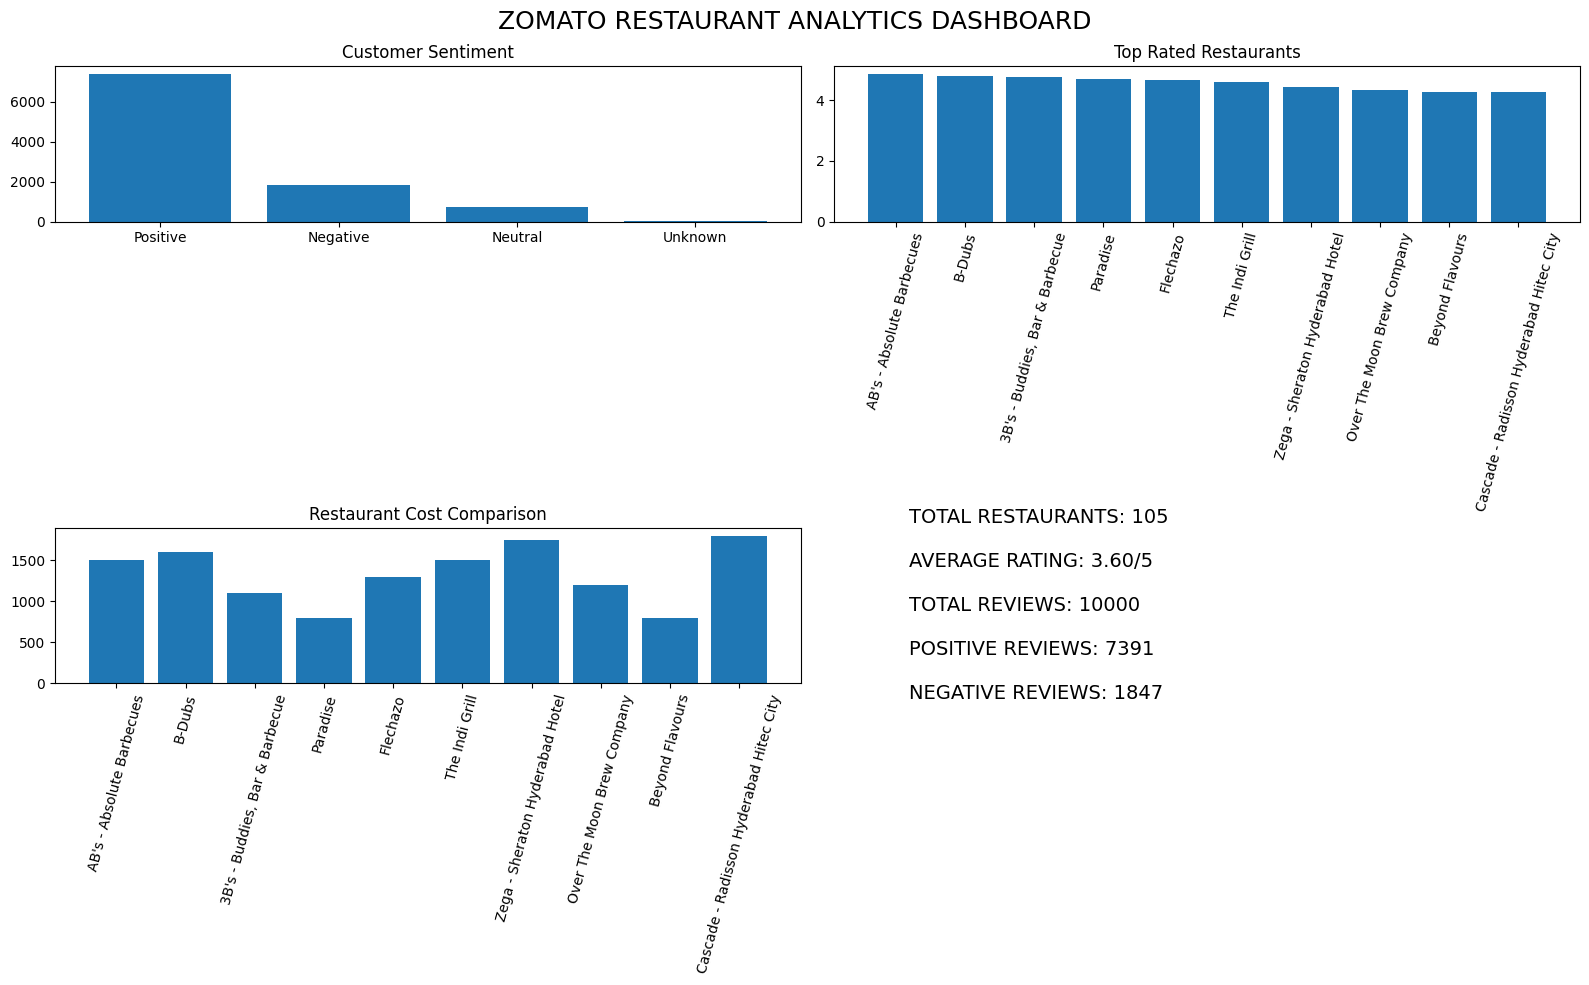

In [23]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Customer Sentiment
sentiment_counts = df1['Sentiment'].value_counts()

axes[0, 0].bar(
    sentiment_counts.index,
    sentiment_counts.values
)
axes[0, 0].set_title("Customer Sentiment")

# 2. Top Rated Restaurants
top10 = restaurants.sort_values(
    by='Average_Rating',
    ascending=False
).head(10)

axes[0, 1].bar(
    top10['Restaurant'],
    top10['Average_Rating']
)
axes[0, 1].set_title("Top Rated Restaurants")
axes[0, 1].tick_params(axis='x', rotation=75)

# 3. Restaurant Cost
axes[1, 0].bar(
    top10['Restaurant'],
    top10['Cost']
)
axes[1, 0].set_title("Restaurant Cost Comparison")
axes[1, 0].tick_params(axis='x', rotation=75)

# 4. Project Statistics
axes[1, 1].axis('off')

stats = (
    f"TOTAL RESTAURANTS: {len(restaurants)}\n\n"
    f"AVERAGE RATING: "
    f"{restaurants['Average_Rating'].mean():.2f}/5\n\n"
    f"TOTAL REVIEWS: {len(df1)}\n\n"
    f"POSITIVE REVIEWS: "
    f"{(df1['Sentiment'] == 'Positive').sum()}\n\n"
    f"NEGATIVE REVIEWS: "
    f"{(df1['Sentiment'] == 'Negative').sum()}"
)

axes[1, 1].text(
    0.1, 0.5,
    stats,
    fontsize=14,
    verticalalignment='center'
)

plt.suptitle(
    "ZOMATO RESTAURANT ANALYTICS DASHBOARD",
    fontsize=18
)

plt.tight_layout()

plt.savefig(
    "Zomato_Analytics_Dashboard.png",
    dpi=300
)

plt.show()

In [24]:
test_cases = [
    ("Biryani", 800),
    ("Pizza", 1000),
    ("Chinese", 700),
    ("North Indian", 1000)
]

for cuisine, budget in test_cases:

    print("\nCuisine:", cuisine)
    print("Budget: ₹", budget)

    result = final_recommendations(
        cuisine,
        budget,
        top_n=5
    )

    if result.empty:
        print("No matching restaurants found")
    else:
        display(result)


Cuisine: Biryani
Budget: ₹ 800


,Restaurant,Cuisines,Cost,Average_Rating,Similarity,Final_Score
1,Paradise,"Biryani, North Indian, Chinese",800,4.70,0.704989,0.775492
52,Biryanis And More,"North Indian, Biryani, Chinese",500,3.74,0.704989,0.717892
35,Green Bawarchi Restaurant,"North Indian, Chinese, Biryani",700,3.49,0.704989,0.702892
51,Hitech Bawarchi Food Zone,"Biryani, North Indian, Chinese",500,3.05,0.704989,0.676492
19,Pakwaan Grand,"North Indian, Chinese, Biryani",400,2.71,0.704989,0.656092



Cuisine: Pizza
Budget: ₹ 1000


,Restaurant,Cuisines,Cost,Average_Rating,Similarity,Final_Score
88,Domino's Pizza,"Fast Food, Pizza",400,3.09,0.784135,0.734294



Cuisine: Chinese
Budget: ₹ 700


,Restaurant,Cuisines,Cost,Average_Rating,Similarity,Final_Score
64,Hyderabad Chefs,"North Indian, Chinese",600,3.810,0.660032,0.690623
57,Being Hungry,"North Indian, Chinese",450,3.660,0.660032,0.681623
81,Delhi-39,"North Indian, Chinese",600,2.975,0.660032,0.640523
95,Desi Bytes,"North Indian, Chinese",400,2.900,0.660032,0.636023
17,Hotel Zara Hi-Fi,"Chinese, North Indian",400,2.400,0.660032,0.606023



Cuisine: North Indian
Budget: ₹ 1000


,Restaurant,Cuisines,Cost,Average_Rating,Similarity,Final_Score
16,NorFest - The Dhaba,North Indian,550,4.03,1.000000,0.941800
98,Triptify,North Indian,400,3.55,1.000000,0.913000
20,13 Dhaba,North Indian,450,3.48,1.000000,0.908800
64,Hyderabad Chefs,"North Indian, Chinese",600,3.81,0.751237,0.754466
57,Being Hungry,"North Indian, Chinese",450,3.66,0.751237,0.745466


In [25]:
# 1. Save restaurant data with ratings
restaurants.to_csv(
    "Zomato_Restaurant_Analysis.csv",
    index=False
)

# 2. Save customer sentiment results
df1.to_csv(
    "Zomato_Sentiment_Analysis.csv",
    index=False
)

# 3. Save final recommendations
final_result = final_recommendations(
    "Biryani", 800, 5
)

final_result.to_csv(
    "Zomato_Final_Recommendations.csv",
    index=False
)

print("All project results saved successfully!")

All project results saved successfully!


In [26]:
readme = """
# Zomato AI-Powered Restaurant Recommendation System

## Project Overview
An AI-powered restaurant recommendation system
that suggests restaurants based on cuisine preference,
budget and customer ratings.

## Features
- Cuisine-based recommendations
- TF-IDF vectorization
- Cosine similarity
- Budget filtering
- Customer rating analysis
- Sentiment analysis
- Weighted recommendation scoring
- CSV download
- Analytics dashboard
- Gradio user interface

## Technologies Used
- Python
- Pandas
- Scikit-learn
- Matplotlib
- VADER Sentiment
- Gradio
- Google Colab

## Recommendation Method
Final Score =
70% Cuisine Similarity + 30% Normalized Rating

## Dataset
Zomato restaurant metadata and customer reviews.

## Developed As
Machine Learning Project
"""

with open("README.md", "w") as file:
    file.write(readme)

print("README.md created successfully!")

README.md created successfully!


In [27]:
import os
import zipfile

project_files = [
    "README.md",
    "Zomato_Restaurant_Analysis.csv",
    "Zomato_Sentiment_Analysis.csv",
    "Zomato_Final_Recommendations.csv",
    "Zomato_Analytics_Dashboard.png"
]

with zipfile.ZipFile(
    "Zomato_Recommendation_Project.zip", "w"
) as zip_file:

    for file in project_files:
        if os.path.exists(file):
            zip_file.write(file)
            print("Added:", file)
        else:
            print("Not found:", file)

print("\nProject ZIP created successfully!")

Added: README.md
Added: Zomato_Restaurant_Analysis.csv
Added: Zomato_Sentiment_Analysis.csv
Added: Zomato_Final_Recommendations.csv
Added: Zomato_Analytics_Dashboard.png

Project ZIP created successfully!


In [28]:
from google.colab import files

files.download("Zomato_Recommendation_Project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>